# Understanding mortgage cashflows and value

A lender advances EUR 250,000 for a home purchase. The borrower repays the
mortgage over thirty years, from 24 February 2026 to 24 February 2056, through
360 monthly payments. A 6% fixed coupon determines interest on the outstanding
balance. Early payments consist largely of interest; as the balance falls,
more of each payment repays principal.

We follow that balance through the full term, then compare floating interest
and a five-year introductory fixed period. The cashflows provide the basis
for present value and par lending-rate calculations. A funding curve, market
scenarios, prepayment assumptions and borrower credit then show how the
expected income stream can differ from its contractual schedule.

The market is an illustrative EUR snapshot dated 24 February 2026. We take
the lender's `LongReceive` position and report amounts in EUR. Rates are
decimal fractions: `0.06` means 6%, and `0.01` means 100 bp.

`LoanPricer` projects expected receipts deterministically. Bounded coupons
use resolved rates without option time value, and the CDS-based survival
curve is an illustrative credit proxy. [Setup](../../README.md#install-and-run).


## The agreement and the market

Our loan pays monthly, with accrual periods running from the 24th of one month
to the 24th of the next. Interest uses Actual/360. If a payment falls on a
non-business day, the Following convention moves it to the next TARGET business
day; the accrual period keeps its original dates.

The market inputs cover the mortgage's full term. Short deposits anchor the
front of each curve. ESTR OIS quotes are 3%; EURIBOR12m deposits are 4%
through one year, followed by swap quotes of 3.70% at five years, 4.50% at
twenty years, and 4.15% at thirty-five years. The shaped EURIBOR inputs
let us see how different future reset periods affect mortgage payments. The
context constructs an ESTR discount curve and a separate EURIBOR projection
curve from those illustrative quotes.
A fixed-income discount policy maps EUR mortgage payments to ESTR. The context
also uses ESTR as its collateral convention. We introduce the borrower credit
curve later, using the example's CDS quotes through 35 years as a credit proxy.
Entering `with context:` activates the context; pricing requests construct the market dependencies.

A `Loan` records the payment agreement. Wrapping it in a `Trade` creates the
lender's position, whose future receipts have positive amounts.
`Side.PayShort` reverses the reported cashflow and value signs.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
import quantsupport as qs
from market_data import load_loan_market


pd.set_option("display.float_format", lambda value: f"{value:,.2f}")
valuation_date = qs.Date(year=2026, month=2, day=24)
maturity_date = valuation_date + qs.Period(length=30, units=qs.TimeUnit.Years)
calendar = qs.Calendar.TARGET
annual_fixed_coupon = 0.06
fixed_rate = qs.InterestRate(
    rate=annual_fixed_coupon,
    day_counter=qs.DayCounter.Actual360,
    compounding=qs.Compounding.Simple,
    frequency=qs.Frequency.Annual,
)
principal = 250_000.0
introductory_years = 5
market = load_loan_market()
known_fixings = qs.FixingStore()
estr_policy = qs.FixedIncomeDiscountPolicy(
    discount_curve_by_currency={qs.Currency.EUR: qs.MarketIndex.ESTR}
)
loan_configuration = qs.PricerConfiguration.loan()
context = qs.PricingContext(
    quotes=market.quotes,
    curves=market.curves,
    fixings=known_fixings,
    csa_policy=market.csa_policy,
    fixed_income_policy=estr_policy,
    pricer_configurations=[loan_configuration],
)

french = qs.LoanRepaymentStructure.french()
requests = [qs.Request.Value, qs.Request.Cashflows, qs.Request.Sensitivities]
monthly_payments = 360
loan_terms = {
    "start_date": valuation_date,
    "maturity_date": maturity_date,
    "notional": principal,
    "currency": qs.Currency.EUR,
    "payment_frequency": qs.Frequency.Monthly,
    "day_counter": qs.DayCounter.Actual360,
    "calendar": calendar,
    "business_day_convention": qs.BusinessDayConvention.Following,
    "fixing_lag": 2,
}


## How a monthly payment is formed

French amortization combines interest and principal in a level regular payment.
At the start of a period the borrower owes $B_{i-1}$. With annual coupon $r$ and
accrual fraction $\tau_i$, interest is $I_i=B_{i-1}r\tau_i$. The principal part
of payment $A$ is $Q_i=A-I_i$, leaving $B_i=B_{i-1}-Q_i$ outstanding.

For our first period, 24 February to 24 March, Actual/360 gives $28/360$ and
interest of $250{,}000\times6\%\times28/360=1{,}166.67$. A month with more accrual
days earns more interest on the same opening balance. The day-count convention
therefore matters even though payments occur monthly.

In [2]:
first_accrual_end = valuation_date + qs.Period(length=1, units=qs.TimeUnit.Months)
accrual_comparison = []
for label, basis in [
    ("Actual/360", qs.DayCounter.Actual360),
    ("Actual/365", qs.DayCounter.Actual365),
    ("30/360", qs.DayCounter.Thirty360),
]:
    fraction = basis.year_fraction(start=valuation_date, end=first_accrual_end)
    accrual_comparison.append(
        {
            "Accrual basis": label,
            "Year fraction": fraction,
            "First-period interest (EUR)": principal * annual_fixed_coupon * fraction,
        }
    )
display(
    pd.DataFrame(accrual_comparison)
    .set_index("Accrual basis")
    .style.format({"Year fraction": "{:.6f}", "First-period interest (EUR)": "{:,.2f}"})
)


,Year fraction,First-period interest (EUR)
Accrual basis,,
Actual/360,0.077778,"1,166.67"
Actual/365,0.076712,"1,150.68"
30/360,0.083333,"1,250.00"


The builder solves the level payment using every period's accrual fraction.
Writing $a_k=\prod_{j=1}^{k}(1+r\tau_j)^{-1}$, the payment that repays the loan
in $n$ periods is

$$A=\frac{B_0}{\sum_{k=1}^{n}a_k}.$$

These factors describe the contractual amortization calculation. The chosen
Actual/360 basis enters both interest and the principal schedule. The library
stores each opening coupon notional and each principal redemption when it
constructs the loan.

`FixedRateCoupon(rate=fixed_rate)` supplies the native fixed coupon definition.
`InterestRate` carries its rate, day count, compounding, and frequency. The `coupons` list is
positional: its last entry continues through the remaining payment periods.
A single fixed coupon therefore covers the whole 30-year term. The pricer's
cashflow request returns interest and principal as separate rows; we arrange
them by payment date to read the borrower's monthly payment.

We evaluate loans with `context.evaluate(trade, requests)`, the same entry
point used for swaps, bonds and caps. `qs.Trade` supplies the lender's position;
the context dispatches directly to the core Rust loan pricer. The same native
path evaluates loan positions in portfolios and scenarios.

Later sections select `rebuild_amortization_for_fair_rate` or
`refinancing_benchmark_index` through `PricerConfiguration.loan(...)` with typed Python arguments.
Discounting follows `context.fixed_income_policy` throughout the study.


In [3]:
fixed = qs.Loan(
    identifier="FIXED",
    coupons=[qs.FixedRateCoupon(rate=fixed_rate)],
    repayment=french,
    **loan_terms,
)
with context:
    fixed_result = context.evaluate(
        trade=qs.Trade(
            instrument=fixed, trade_date=valuation_date, side=qs.Side.LongReceive
        ),
        requests=requests,
    )

fixed_payments = fixed_result.cashflows.pivot_table(
    index="payment_date", columns="type", values="amount", aggfunc="sum", fill_value=0
).rename(columns={"FixedRateCoupon": "Interest", "Redemption": "Principal repaid"})
fixed_payments["Payment"] = (
    fixed_payments["Interest"] + fixed_payments["Principal repaid"]
)
fixed_payments["Opening balance"] = principal - fixed_payments[
    "Principal repaid"
].cumsum().shift(fill_value=0)
fixed_payments["Closing balance"] = (
    principal - fixed_payments["Principal repaid"].cumsum()
).clip(lower=0)
display(
    fixed_payments[
        [
            "Opening balance",
            "Interest",
            "Principal repaid",
            "Payment",
            "Closing balance",
        ]
    ].head(6)
)


type,Opening balance,Interest,Principal repaid,Payment,Closing balance
payment_date,,,,,
2026-03-24,"250,000.00","1,166.67",345.95,"1,512.61","249,654.05"
2026-04-24,"249,654.05","1,289.88",222.73,"1,512.61","249,431.32"
2026-05-25,"249,431.32","1,247.16",265.46,"1,512.61","249,165.86"
2026-06-24,"249,165.86","1,287.36",225.26,"1,512.61","248,940.61"
2026-07-24,"248,940.61","1,244.70",267.91,"1,512.61","248,672.70"
2026-08-24,"248,672.70","1,284.81",227.80,"1,512.61","248,444.89"


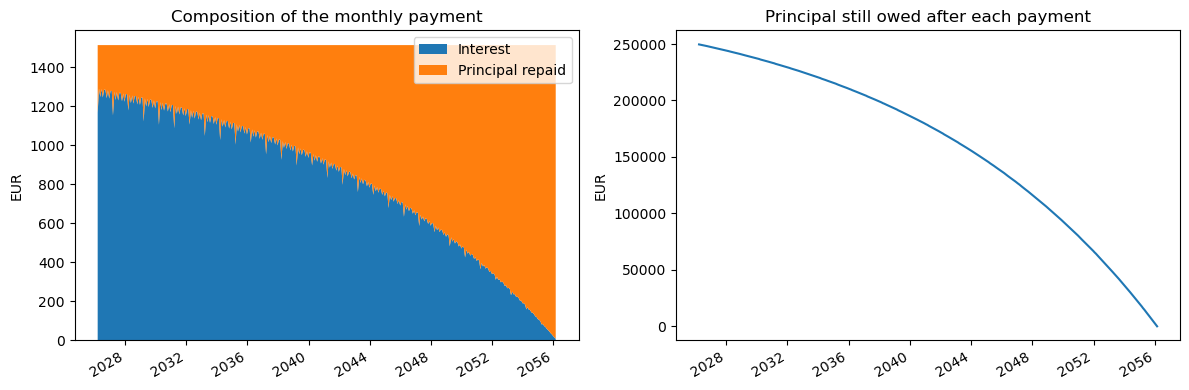

type,Closing balance,Interest paid so far
Mortgage year,,
1,"246,969.20","15,120.55"
5,"232,876.10","73,632.87"
10,"209,682.45","141,196.00"
20,"135,741.07","248,768.16"
30,0.00,"294,540.62"


In [4]:
figure, axes = plt.subplots(1, 2, figsize=(12, 4))
dates = pd.to_datetime(fixed_payments.index)
axes[0].stackplot(
    dates,
    fixed_payments["Interest"],
    fixed_payments["Principal repaid"],
    labels=["Interest", "Principal repaid"],
)
axes[0].set(title="Composition of the monthly payment", ylabel="EUR")
axes[0].legend(loc="upper right")
axes[1].plot(dates, fixed_payments["Closing balance"], color="tab:blue")
axes[1].set(title="Principal still owed after each payment", ylabel="EUR")
figure.autofmt_xdate()
figure.tight_layout()
plt.show()
annual_milestones = fixed_payments.iloc[[11, 59, 119, 239, -1]][
    ["Closing balance"]
].copy()
annual_milestones["Interest paid so far"] = (
    fixed_payments["Interest"].cumsum().iloc[[11, 59, 119, 239, -1]]
)
annual_milestones.index = pd.Index([1, 5, 10, 20, 30], name="Mortgage year")
display(annual_milestones)


The regular payment is EUR 1,512.61. Its first interest component is EUR 1,166.67,
leaving EUR 345.95 to repay principal. April's interest rises to EUR 1,289.88
because its accrual period has 31 days. Over time the interest component falls
and more of each regular payment repays principal.

This is a slow process over a 30-year mortgage. After ten years the borrower
still owes EUR 209,682.45, about 84% of the original advance. After twenty years,
EUR 135,741.07 remains. Total contractual interest reaches EUR 294,540.62 over
the full term. Substantial balances remain exposed to interest rates and borrower
default for decades, making early repayment a major driver of expected income.

The library computes an unrounded schedule; the tables display amounts to two
decimal places.


## Choosing when principal returns

Repayment timing changes both borrower funding and lender exposure. A bullet
loan keeps the full EUR 250,000 outstanding until maturity, so each intervening
payment consists of interest. A balloon loan combines regular amortization with
a specified residual principal amount due at the end.

Here `balloon(residual_fraction=0.25)` reserves EUR 62,500 of original principal for maturity.
For residual $L$, the regular payment becomes

$$A=\frac{B_0-L a_n}{\sum_{k=1}^{n}a_k}.$$

The final receipt includes the regular payment and the residual. We keep the 6%
coupon and market assumptions the same across structures to see how the timing
of principal affects monthly payments, total interest, and receipt value.

In [5]:
repayment_choices = {
    "French": fixed,
    "Bullet": qs.Loan(
        identifier="BULLET",
        coupons=[qs.FixedRateCoupon(rate=fixed_rate)],
        repayment=qs.LoanRepaymentStructure.bullet(),
        **loan_terms,
    ),
    "25% balloon": qs.Loan(
        identifier="BALLOON",
        coupons=[qs.FixedRateCoupon(rate=fixed_rate)],
        repayment=qs.LoanRepaymentStructure.balloon(residual_fraction=0.25),
        **loan_terms,
    ),
}
repayment_comparison = []
with context:
    for label, instrument in repayment_choices.items():
        result = context.evaluate(
            trade=qs.Trade(instrument=instrument, trade_date=valuation_date),
            requests=[qs.Request.Value, qs.Request.Cashflows],
        )
        payments = result.cashflows.groupby("payment_date").amount.sum()
        interest = result.cashflows.loc[
            result.cashflows.type == "FixedRateCoupon", "amount"
        ].sum()
        repayment_comparison.append(
            {
                "Repayment": label,
                "First payment (EUR)": payments.iloc[0],
                "Final payment (EUR)": payments.iloc[-1],
                "Total interest (EUR)": interest,
                "Value of receipts (EUR)": result.price,
            }
        )
display(pd.DataFrame(repayment_comparison).set_index("Repayment"))


,First payment (EUR),Final payment (EUR),Total interest (EUR),Value of receipts (EUR)
Repayment,,,,
French,"1,512.61","1,512.61","294,540.62","358,742.79"
Bullet,"1,166.67","251,291.67","456,541.67","402,421.74"
25% balloon,"1,451.44","63,951.44","335,017.32","369,654.42"


The bullet loan earns interest on the full principal for thirty years. Its
smaller interim payments leave the borrower with the entire EUR 250,000 still
to repay at maturity. The 25% balloon lowers the regular payment to EUR 1,451.44,
with a final EUR 63,951.44 receipt that includes the EUR 62,500 residual.

Both structures keep principal outstanding longer than French amortization.
That increases total interest and the lender's exposure to future market rates
and default. Here the 6% coupon exceeds the ESTR-discounted par rate, so retaining
that balance also increases the present value of the promised receipts.


## Floating interest, annual resets, and an introductory fixed period

A EURIBOR12m loan with a 1% spread earns an annual coupon equal to the applicable
EURIBOR fixing plus 100 basis points. Payment frequency and reset frequency
serve different purposes: this loan pays monthly, while the 12-month index resets
the reference rate once a year. Each of the following twelve monthly coupons
uses that observed rate.

The library takes the reset frequency and observation tenor from the index
metadata. The loan's two-business-day fixing lag places the first observation
on 20 February, before our valuation date. We supply that historical fixing as
4%. Later observations come from the EURIBOR projection curve. Interest accrues
over each monthly period using the loan's Actual/360 convention.

For amortization, we choose an initial all-in rate of 5%. That input determines
the agreed principal amounts. Subsequent fixings determine interest on those
balances, so a reset can change the total monthly payment.

In [6]:
floating = qs.Loan(
    identifier="FLOATING",
    coupons=[qs.FloatingRateCoupon(index=qs.MarketIndex.EURIBOR12m, spread=0.01)],
    repayment=french,
    amortization_rate=0.05,
    **loan_terms,
)
observations = floating.coupon_fixing_requests()
for observation in observations.itertuples(index=False):
    fixing_date = qs.Date.parse(s=observation.fixing_date)
    if fixing_date < valuation_date:
        known_fixings.add(
            index=qs.MarketIndex.parse(s=observation.market_index),
            date=fixing_date,
            value=0.04,
        )
display(
    observations.rename(
        columns={
            "fixing_date": "Observation date",
            "start_date": "Index period start",
            "end_date": "Index period end",
            "market_index": "Index",
        }
    )
)

context.fixings = known_fixings
with context:
    floating_result = context.evaluate(
        trade=qs.Trade(instrument=floating, trade_date=valuation_date),
        requests=requests,
    )
floating_coupons = floating_result.cashflows.loc[
    floating_result.cashflows.type == "FloatingRateCoupon",
    ["payment_date", "fixing", "accrual_period", "amount"],
].copy()
floating_coupons["All-in coupon (%)"] = (floating_coupons.fixing + 0.01) * 100
floating_coupons["EURIBOR fixing (%)"] = floating_coupons.fixing * 100
display(
    floating_coupons.iloc[[0, 1, 11, 12, -1]][
        [
            "payment_date",
            "EURIBOR fixing (%)",
            "All-in coupon (%)",
            "accrual_period",
            "amount",
        ]
    ]
    .rename(
        columns={
            "payment_date": "Payment date",
            "amount": "Interest (EUR)",
            "accrual_period": "Accrual fraction",
        }
    )
    .style.format(
        {
            "Accrual fraction": "{:.6f}",
            "EURIBOR fixing (%)": "{:.4f}",
            "All-in coupon (%)": "{:.4f}",
            "Interest (EUR)": "{:,.2f}",
        }
    )
)


,Index,Observation date,Index period start,Index period end
0,EURIBOR12m,2026-02-20,2026-02-24,2027-02-24
1,EURIBOR12m,2027-02-22,2027-02-24,2028-02-24
2,EURIBOR12m,2028-02-22,2028-02-24,2029-02-26
3,EURIBOR12m,2029-02-22,2029-02-26,2030-02-26
4,EURIBOR12m,2030-02-21,2030-02-25,2031-02-25
5,EURIBOR12m,2031-02-20,2031-02-24,2032-02-24
6,EURIBOR12m,2032-02-20,2032-02-24,2033-02-24
7,EURIBOR12m,2033-02-22,2033-02-24,2034-02-24
8,EURIBOR12m,2034-02-22,2034-02-24,2035-02-26
9,EURIBOR12m,2035-02-22,2035-02-26,2036-02-26


,Payment date,EURIBOR fixing (%),All-in coupon (%),Accrual fraction,Interest (EUR)
0,2026-03-24,4.0000,5.0000,0.077778,972.22
2,2026-04-24,4.0000,5.0000,0.086111,"1,074.75"
22,2027-02-24,4.0000,5.0000,0.086111,"1,061.93"
24,2027-03-24,3.6913,4.6913,0.077778,898.89
718,2056-02-24,2.6090,3.6090,0.086111,4.19


At the second reset, the projected index is about 3.89%, giving an all-in coupon
of about 4.89%. For EURIBOR's simple-rate convention, the forward observation
comes from the projection curve over the full index period:

$$F(t,T)=\frac{P_L(0,t)/P_L(0,T)-1}{\tau_L(t,T)}.$$

Here $P_L$ contains EURIBOR projection discount factors and $\tau_L$ is the
index's Actual/360 accrual fraction over twelve months. Deposit and swap quotes
price cashflows across their quoted maturities. The discount-factor ratio
extracts the return for this particular future index period.

The mortgage has thirty annual observations. Only the first fixing is already
known; the remaining twenty-nine are implied by today's projection curve.
Each monthly coupon applies its annual observation plus the loan spread to
that month's accrual fraction. Future realized rates will depend on how the
market evolves before each fixing date.


A five-year introductory fixed period changes the coupon schedule. In the next
loan, the first sixty monthly periods earn 4%; the remaining periods earn
EURIBOR12m plus 1%. The coupon list ends with the floating definition, which
continues to maturity. The first fixed coupon supplies the initial amortization
rate, giving this agreement a principal schedule based on 4%.

The upper panel shows EURIBOR fixings and the annual coupon rates resolved by
the pricer. The dashed line traces the known first fixing and subsequent
projected resets. After year five, the two floating coupon rates coincide.
Log-linear interpolation of discount factors gives nearly constant forwards
between quote pillars, and each annual observation holds until the next reset.

The lower panel shows the borrower's monthly payments. For a French principal
schedule built at initial rate $r_0$, the payment under actual coupon $r_i$ is

$$A_i=A_0+B_{i-1}(r_i-r_0)\tau_i.$$

Here $A_0$ is the original level payment and $B_{i-1}$ is that period's agreed
opening balance. The floating mortgage uses $r_0=5\%$, so a projected all-in
coupon close to 5% produces a payment close to its original instalment. The
introductory-fixed mortgage uses $r_0=4\%$; interest above that basis increases
its payment after the switch. As the balance falls, the same rate difference
has a smaller effect on the amount paid.


,6% fixed,EURIBOR12m + 1%,"4% for five years, then EURIBOR12m + 1%"
payment_date,,,
2026-03-24,"1,512.61","1,352.95","1,201.77"
2027-02-24,"1,512.61","1,352.95","1,201.77"
2027-03-24,"1,512.61","1,293.81","1,201.77"
2031-02-24,"1,512.61","1,251.82","1,201.77"
2031-03-24,"1,512.61","1,322.26","1,347.57"
2036-02-25,"1,512.61","1,493.77","1,508.55"
2046-02-26,"1,512.61","1,445.38","1,390.50"
2056-02-24,"1,512.61","1,351.34","1,201.37"


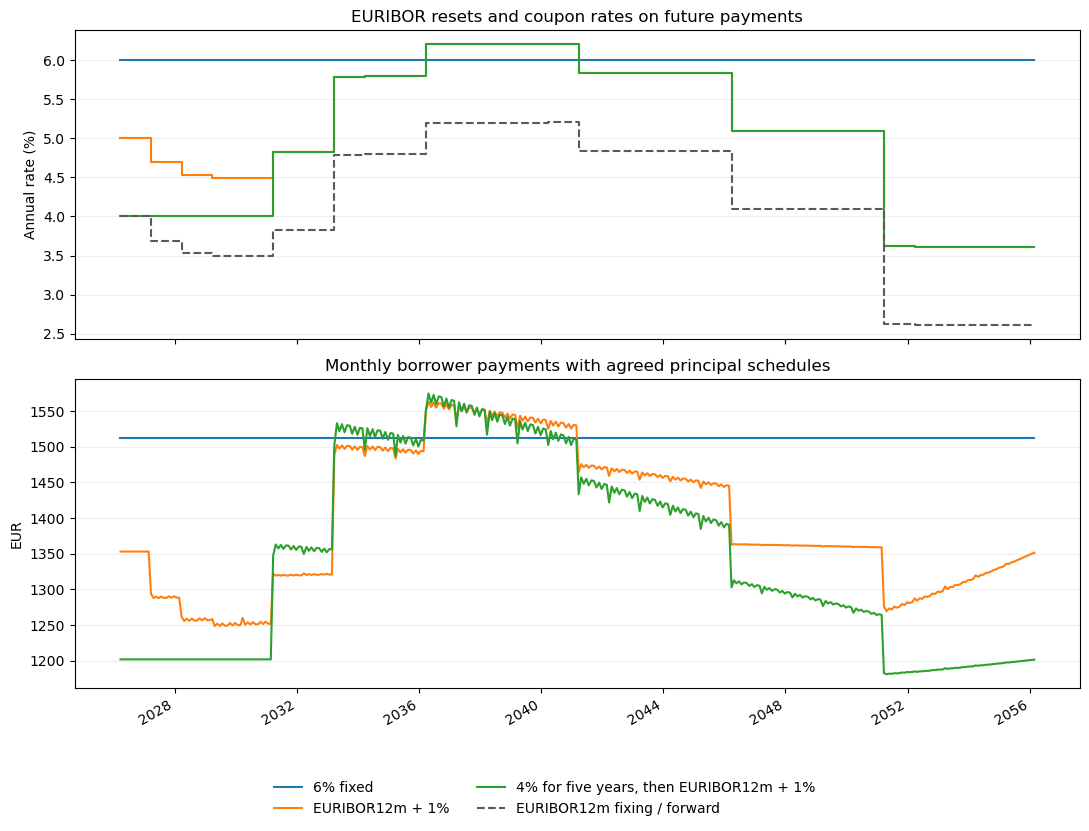

In [7]:
introductory_coupon = qs.FixedRateCoupon(
    rate=qs.InterestRate(
        rate=0.04,
        day_counter=qs.DayCounter.Actual360,
        compounding=qs.Compounding.Simple,
        frequency=qs.Frequency.Annual,
    )
)
floating_coupon = qs.FloatingRateCoupon(index=qs.MarketIndex.EURIBOR12m, spread=0.01)
introductory_periods = introductory_years * 12
mixed = qs.Loan(
    identifier="INTRODUCTORY-FIXED",
    coupons=[introductory_coupon] * introductory_periods + [floating_coupon],
    repayment=french,
    **loan_terms,
)
with context:
    mixed_result = context.evaluate(
        trade=qs.Trade(instrument=mixed, trade_date=valuation_date),
        requests=requests,
    )

payment_paths = pd.DataFrame(
    {
        "6% fixed": fixed_result.cashflows.groupby("payment_date").amount.sum(),
        "EURIBOR12m + 1%": floating_result.cashflows.groupby(
            "payment_date"
        ).amount.sum(),
        "4% for five years, then EURIBOR12m + 1%": mixed_result.cashflows.groupby(
            "payment_date"
        ).amount.sum(),
    }
)
display(payment_paths.iloc[[0, 11, 12, 59, 60, 119, 239, -1]])
mixed_coupons = mixed_result.cashflows.loc[
    mixed_result.cashflows["type"].isin(["FixedRateCoupon", "FloatingRateCoupon"])
].copy()
mixed_coupon_rates = pd.Series(4.0, index=payment_paths.index)
floating_periods = mixed_coupons["type"].eq("FloatingRateCoupon")
floating_dates = mixed_coupons.loc[floating_periods, "payment_date"]
mixed_coupon_rates.loc[floating_dates] = (
    mixed_coupons.loc[floating_periods, "fixing"].to_numpy() + 0.01
) * 100
coupon_paths = pd.DataFrame(
    {
        "6% fixed": pd.Series(6.0, index=fixed_payments.index),
        "EURIBOR12m + 1%": pd.Series(
            (floating_coupons.fixing.to_numpy() + 0.01) * 100,
            index=floating_coupons.payment_date,
        ),
        "4% for five years, then EURIBOR12m + 1%": mixed_coupon_rates,
    }
)
figure, axes = plt.subplots(2, 1, figsize=(11, 8.5), sharex=True)
dates = pd.to_datetime(payment_paths.index)
for label in payment_paths:
    axes[0].step(dates, coupon_paths[label], where="post", label=label)
    axes[1].plot(dates, payment_paths[label], label=label)
axes[0].step(
    dates,
    floating_coupons.fixing.to_numpy() * 100,
    where="post",
    color="0.35",
    linestyle="--",
    label="EURIBOR12m fixing / forward",
)
axes[0].set(
    title="EURIBOR resets and coupon rates on future payments", ylabel="Annual rate (%)"
)
axes[1].set(
    title="Monthly borrower payments with agreed principal schedules", ylabel="EUR"
)
for axis in axes:
    axis.grid(axis="y", alpha=0.2)
figure.legend(
    handles=axes[0].get_lines(),
    loc="lower center",
    bbox_to_anchor=(0.5, 0.02),
    ncol=2,
    frameon=False,
)
figure.autofmt_xdate()
figure.tight_layout(rect=(0, 0.12, 1, 1))
plt.show()


Floating coupons can also have an all-in floor and cap. For a 2% floor and
4.5% cap, the coupon is $\min(4.5\%,\max(2\%,L+1\%))$, where $L$ is the index
observation. The initial 4% fixing would otherwise produce a 5% coupon, so the
cap limits the first year's interest income.

`OptionEmbeddedCoupon` accepts the same `PayoffOps` expression tree as Rust.
`Index` is the resolved fixing; arithmetic, `min`, and `max` combine expressions.
We include the lending margin inside the expression so the bounds apply to the
all-in rate. The coupon's separate `spread` parameter would be added after the
payoff. The same operations can express gearing, for example
`(2 * qs.PayoffOps.Index + 0.005).max(0.02)`.

`LoanPricer` applies these bounds to the resolved index observations. The result
shows the projected cash payments under those rates. A valuation of the embedded
interest-rate option's time value would additionally require a volatility model.

In [8]:
bounded = qs.Loan(
    identifier="FLOOR-AND-CAP",
    coupons=[
        qs.OptionEmbeddedCoupon(
            index=qs.MarketIndex.EURIBOR12m,
            payoff=(qs.PayoffOps.Index + 0.01).max(0.02).min(0.045),
            day_counter=qs.DayCounter.Actual360,
        )
    ],
    repayment=french,
    amortization_rate=0.05,
    **loan_terms,
)
with context:
    bounded_result = context.evaluate(
        trade=qs.Trade(instrument=bounded, trade_date=valuation_date),
        requests=[qs.Request.Value, qs.Request.Cashflows],
    )
display(
    pd.DataFrame(
        {
            "Unbounded floating": floating_result.cashflows.groupby(
                "payment_date"
            ).amount.sum(),
            "2% floor, 4.5% cap": bounded_result.cashflows.groupby(
                "payment_date"
            ).amount.sum(),
        }
    ).iloc[[0, 11, 12, -1]]
)


,Unbounded floating,"2% floor, 4.5% cap"
payment_date,,
2026-03-24,"1,352.95","1,255.73"
2027-02-24,"1,352.95","1,246.76"
2027-03-24,"1,293.81","1,257.15"
2056-02-24,"1,351.34","1,351.34"


## Present value and the coupon that lends at par

A loan's value depends on the timing of its income. For discount factors
$D(0,t_i)$ and future receipts $C_i$, the lender's receipt value is

$$V_{\mathrm{receipts}}=\sum_i D(0,t_i)\,\mathbb{E}[C_i].$$

The `price` returned by the loan pricer is this value of future receipts. At
origination the lender also advances EUR 250,000, giving an initial net value of
$V_{\mathrm{receipts}}-250{,}000$. Payment dates strictly after the valuation
date enter the receipt value. Our example starts on the valuation date, so the
full advance occurs today.

With a 6% fixed coupon and the selected ESTR discount curve, the loan trades at a
premium to its original principal. The nominal interest total and present value
answer different financial questions: the former measures currency received
over the life of the loan, while the latter accounts for when it arrives.

In [9]:
origination_values = []
for label, result in [
    ("6% fixed", fixed_result),
    ("EURIBOR12m + 1%", floating_result),
    ("Introductory fixed", mixed_result),
]:
    origination_values.append(
        {
            "Agreement": label,
            "Value of receipts (EUR)": result.price,
            "Advance today (EUR)": principal,
            "Lender value after advance (EUR)": result.price - principal,
        }
    )
display(pd.DataFrame(origination_values).set_index("Agreement"))


,Value of receipts (EUR),Advance today (EUR),Lender value after advance (EUR)
Agreement,,,
6% fixed,"358,742.79","250,000.00","108,742.79"
EURIBOR12m + 1%,"331,004.10","250,000.00","81,004.10"
Introductory fixed,"320,936.48","250,000.00","70,936.48"


### Selecting a different discount policy

Assign a `qs.FixedIncomeDiscountPolicy` to `context.fixed_income_policy`, then
call `context.evaluate(...)` as usual. The mapping selects a discount curve by
payment currency. Its index must identify a curve configured in `context.curves`;
assigning the policy does not create that curve. Our market already contains
both ESTR and EURIBOR12m, so we can compare them directly.

The following cell selects EURIBOR12m for EUR receipts and restores ESTR for
the remaining study. The fixed loan's payments stay the same; only their
present value changes. For a floating loan, the coupon's index still selects
its projection curve. `context.csa_policy` continues to specify the collateral
convention used for market construction.

You can also pass `fixed_income_policy=...` when creating `PricingContext`.
Setting `context.fixed_income_policy = None` restores the default policy based
on the context's base currency and curve.
The funding section below applies the same mapping to a composite cost-of-funds
curve.


In [10]:
euribor_discount_policy = qs.FixedIncomeDiscountPolicy(
    discount_curve_by_currency={qs.Currency.EUR: qs.MarketIndex.EURIBOR12m}
)
context.fixed_income_policy = euribor_discount_policy
try:
    with context:
        fixed_on_euribor = context.evaluate(
            qs.Trade(fixed, valuation_date, qs.Side.LongReceive),
            [qs.Request.Value, qs.Request.Cashflows],
        )
finally:
    context.fixed_income_policy = estr_policy

display(
    pd.DataFrame(
        {"Value of receipts (EUR)": [fixed_result.price, fixed_on_euribor.price]},
        index=pd.Index(["ESTR", "EURIBOR12m"], name="Discount curve"),
    )
)


,Value of receipts (EUR)
Discount curve,
ESTR,"358,742.79"
EURIBOR12m,"307,937.61"


`FairRate` solves the coupon or floating spread that makes the value of receipts
equal to the value of the advance. There are two useful ways to pose that problem.
An existing principal schedule can be retained while changing its coupon. A new
loan can instead have its amortization recalculated for each candidate rate.

`rebuild_amortization_for_fair_rate` selects between those two assumptions.
With `False`, the solver keeps the agreed principal amounts. With `True`, it
rebuilds the French payment using the trial fixed coupon, or the first observed
index rate plus the trial floating spread. The settings can give
different par rates because they change the timing of principal repayments.
The library supports this solve at or before origination for uniform fixed or
unbounded floating coupons.

We set the amortization option with `PricerConfiguration.loan(...)`
in the context before calling `context.evaluate(...)`. The context
dispatches directly to the Rust loan pricer and supplies its fixed-income
discount policy. The `finally` block restores the default loan configuration
for the remaining study.


In [11]:
fair_rate_comparison = []
try:
    with context:
        for rebuild, schedule in [
            (False, "Keep the agreed principal schedule"),
            (True, "Rebuild principal at the trial rate"),
        ]:
            context.pricer_configurations = [qs.PricerConfiguration.loan(
                rebuild_amortization_for_fair_rate=rebuild,
            )]
            fixed_fair = context.evaluate(
                trade=qs.Trade(instrument=fixed, trade_date=valuation_date),
                requests=[qs.Request.FairRate(0)],
            ).fair_rate
            floating_fair = context.evaluate(
                trade=qs.Trade(instrument=floating, trade_date=valuation_date),
                requests=[qs.Request.FairRate(0)],
            ).fair_rate
            fair_rate_comparison.append(
                {
                    "Principal assumption": schedule,
                    "Par fixed coupon (%)": fixed_fair * 100,
                    "Par EURIBOR spread (bp)": floating_fair * 10_000,
                }
            )
finally:
    context.pricer_configurations = [loan_configuration]
display(
    pd.DataFrame(fair_rate_comparison)
    .set_index("Principal assumption")
    .style.format("{:,.6f}")
)


,Par fixed coupon (%),Par EURIBOR spread (bp)
Principal assumption,,
Keep the agreed principal schedule,2.958781,-133.298963
Rebuild principal at the trial rate,2.958477,-131.947212


In this illustrative market, the EURIBOR projection curve produces a higher
benchmark coupon than the ESTR-discounted par lending rate requires. The par
floating spread is consequently negative. It is the adjustment to the benchmark
needed under these particular cashflow and discount assumptions. The fixed
solution is an annual coupon; the floating solution is a margin added to EURIBOR.

## Valuing the loan against the lender's cost of funds

A lender funding an asset at EURIBOR plus a treasury spread needs the loan's
income to cover both components. We can express that funding hurdle as a discount
curve and ask what the agreed receipts are worth on that basis. This also gives
us the coupon or lending margin required to cover funding at origination.

We use the existing EURIBOR12m curve as the benchmark and introduce a separate
funding spread term structure. Its continuously compounded zero spreads rise
from **50 bp today to 100 bp at five years, 125 bp at twenty years, and
140 bp at thirty years**. A final pillar at thirty-five years is 150 bp.
Interpolation is linear on Actual/360 time. These are illustrative treasury
assumptions; the spread is charged over the EURIBOR benchmark.

For spread $s(T)$ and year fraction $\tau(0,T)$, the composite curve has

$$D_{\mathrm{funding}}(0,T)
  =D_{\mathrm{EURIBOR}}(0,T)\,D_{\mathrm{spread}}(0,T)
  =D_{\mathrm{EURIBOR}}(0,T)\,e^{-s(T)\tau(0,T)}.$$

Equivalently, the continuously compounded zero rate is
$z_{\mathrm{funding}}(T)=z_{\mathrm{EURIBOR}}(T)+s(T)$. The EURIBOR zero rate here
is obtained from its discount factor on the same time basis. This preserves the
compounding conventions of the underlying deposit and swap quotes.

The spread and composite curves are `CurveConfiguration` entries in the same
`curves` list as ESTR and EURIBOR. Pricing requests build their dependencies,
including under each scenario. Assigning a `FixedIncomeDiscountPolicy` to
`context.fixed_income_policy` selects the funding curve for the next
`context.evaluate(...)` call. The same loan agreements and pricing requests
produce the funding values below.

In [12]:
cost_of_funds_index = qs.MarketIndex.other(name="COSTOFFUNDS")
funding_tenors = [
    qs.Period(length=0, units=qs.TimeUnit.Days),
    *[
        qs.Period(length=years, units=qs.TimeUnit.Years)
        for years in [1, 5, 10, 20, 30, 35]
    ],
]
funding_spreads = [0.0050, 0.0075, 0.0100, 0.0115, 0.0125, 0.0140, 0.0150]
display(
    pd.DataFrame(
        {
            "Tenor": [str(tenor) for tenor in funding_tenors],
            "Continuous zero funding spread (bp)": [
                rate * 10_000 for rate in funding_spreads
            ],
        }
    ).set_index("Tenor")
)

funding_spread_index = qs.MarketIndex.other(name="FUNDINGSPREAD")
spread_configuration = qs.CurveConfiguration(
    market_index=funding_spread_index,
    day_counter=qs.DayCounter.Actual360,
    interpolator=qs.Interpolator.Linear,
    enable_extrapolation=False,
    quotes=[f"ZeroRate_EUR_FUNDINGSPREAD_{tenor}" for tenor in funding_tenors],
)
funding_configuration = qs.CurveConfiguration.composite(market_index=cost_of_funds_index, base_index=qs.MarketIndex.EURIBOR12m, spread_index=funding_spread_index)
funding_policy = qs.FixedIncomeDiscountPolicy(
    discount_curve_by_currency={qs.Currency.EUR: cost_of_funds_index}
)
benchmark_policy = qs.FixedIncomeDiscountPolicy(
    discount_curve_by_currency={qs.Currency.EUR: qs.MarketIndex.EURIBOR12m}
)
funding_quote_records = [
    {"identifier": identifier, **dict(zip(("mid", "bid", "ask"), market.quotes.levels(identifier)))}
    for identifier in market.quotes.identifiers()
]
funding_quote_records += [
    {"identifier": f"ZeroRate_EUR_FUNDINGSPREAD_{tenor}", "mid": rate}
    for tenor, rate in zip(funding_tenors, funding_spreads)
]
context.quotes = qs.QuoteStore.from_dict({"reference_date": str(valuation_date), "quotes": funding_quote_records})
context.curves = market.curves + [spread_configuration, funding_configuration]
context.fixed_income_policy = funding_policy

funding_values = []
funding_base_results = {}
with context:
    for label, instrument in [("6% fixed", fixed), ("EURIBOR12m + 1%", floating)]:
        for discount_basis, policy in [
            ("ESTR", estr_policy),
            ("EURIBOR12m", benchmark_policy),
            ("EURIBOR12m + funding spread", funding_policy),
        ]:
            context.fixed_income_policy = policy
            result = context.evaluate(
                trade=qs.Trade(instrument=instrument, trade_date=valuation_date),
                requests=[
                    qs.Request.Value,
                    qs.Request.FairRate(0),
                    qs.Request.Sensitivities,
                ],
            )
            if discount_basis == "EURIBOR12m + funding spread":
                funding_base_results[label] = result
            funding_values.append(
                {
                    "Loan": label,
                    "Discount basis": discount_basis,
                    "Value of receipts (EUR)": result.price,
                    "Value after advance (EUR)": result.price - principal,
                    "Par fixed coupon (%)": (
                        result.fair_rate * 100 if instrument is fixed else None
                    ),
                    "Par EURIBOR margin (bp)": (
                        result.fair_rate * 10_000 if instrument is floating else None
                    ),
                }
            )
display(
    pd.DataFrame(funding_values)
    .set_index(["Loan", "Discount basis"])
    .style.format("{:,.2f}", na_rep="—")
)


,Continuous zero funding spread (bp)
Tenor,
0D,50.00
1Y,75.00
5Y,100.00
10Y,115.00
20Y,125.00
30Y,140.00
35Y,150.00


The fixed mortgage's receipt value falls from EUR 358,742.79 under ESTR
discounting to EUR 303,807.00 on EURIBOR and EUR 264,555.88 after the funding
spread. Its funding-based par coupon is about 5.49%. At the agreed 6% coupon,
the receipt value exceeds the original advance by EUR 14,555.88.

For the floating mortgage, the funding-based par margin is 112.22 bp. Its agreed
100 bp margin falls short of that hurdle: receipts are worth EUR 246,596.61,
leaving a value of EUR -3,403.39 after the advance. A spread that covers funding
at the front of the curve can be insufficient over a thirty-year income stream
when treasury funding spreads rise with maturity.

The fair-rate calculations retain each agreed principal schedule, using the
default `rebuild_amortization_for_fair_rate=False`. Prepayment and borrower
recovery will change expected receipts in the following sections.


### Funding-spread sensitivities

A wider treasury funding spread reduces the value of each remaining receipt.
The effect depends on when principal and interest return: a spread pillar near
the mortgage's large later balances carries more exposure than one near its
last small payments. Linear interpolation distributes that exposure between
the neighbouring funding pillars.

We request `qs.Request.Sensitivities` with the funding discount policy selected.
The result includes derivatives with respect to the original funding zero
spreads, labelled `ZeroRate_EUR_FUNDINGSPREAD_<tenor>`. A `value` is EUR per unit decimal
spread; multiplying by `0.0001` gives the approximate EUR value change for a
**+1 bp** increase in that pillar, holding other inputs fixed.

The first table separates funding spreads from the benchmark quotes. The next
table and chart isolate each funding-spread maturity. Adding those bucket
sensitivities gives the first-order effect of a parallel +1 bp funding move.


Loan,6% fixed,EURIBOR12m + 1%
Curve input,,
ESTR market quotes,-4.20,+0.34
EURIBOR market quotes,-279.24,-8.14
Funding zero spreads,-295.46,-275.84


Loan,6% fixed,EURIBOR12m + 1%
Funding spread tenor,,
0D,-0.2960,-0.2647
1Y,-8.1762,-6.8757
5Y,-33.3653,-29.6330
10Y,-83.3903,-83.1543
20Y,-115.4609,-107.9241
30Y,-54.7719,-47.9881
35Y,+0.0000,+0.0000


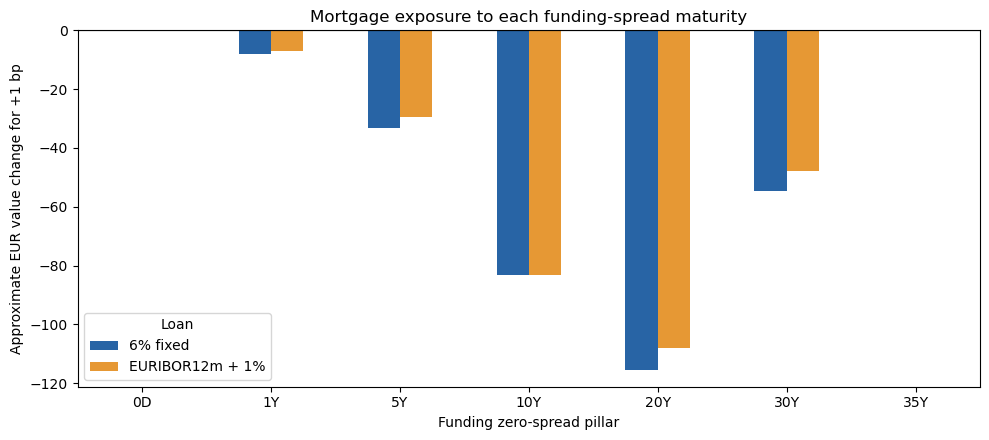

In [13]:
def curve_input_family(pillar):
    if "FUNDINGSPREAD" in pillar:
        return "Funding zero spreads"
    if "EURIBOR" in pillar:
        return "EURIBOR market quotes"
    return "ESTR market quotes"


context.fixed_income_policy = funding_policy
funding_risks = []
with context:
    for label, instrument in [("6% fixed", fixed), ("EURIBOR12m + 1%", floating)]:
        result = context.evaluate(
            trade=qs.Trade(instrument=instrument, trade_date=valuation_date),
            requests=[qs.Request.Sensitivities],
        )
        risk = result.sensitivities.copy()
        risk["Loan"] = label
        risk["EUR change for +1bp"] = risk.value * 0.0001
        risk["Curve input"] = risk["pillar"].map(curve_input_family)
        funding_risks.append(risk)
funding_risk = pd.concat(funding_risks, ignore_index=True)
funding_pv01 = funding_risk.pivot_table(
    index="Curve input",
    columns="Loan",
    values="EUR change for +1bp",
    aggfunc="sum",
    fill_value=0,
)
display(funding_pv01.style.format("{:+,.2f}"))

funding_pillar_labels = [
    f"ZeroRate_EUR_FUNDINGSPREAD_{tenor}" for tenor in funding_tenors
]
funding_spread_sensitivities = (
    funding_risk.loc[funding_risk.pillar.isin(funding_pillar_labels)]
    .pivot(index="pillar", columns="Loan", values="EUR change for +1bp")
    .reindex(funding_pillar_labels)
)
funding_spread_sensitivities.index = pd.Index(
    [str(tenor) for tenor in funding_tenors], name="Funding spread tenor"
)
display(funding_spread_sensitivities.style.format("{:+,.4f}"))

axis = funding_spread_sensitivities.plot.bar(
    figsize=(10, 4.5), color=["#2864a5", "#e69834"]
)
axis.axhline(0, color="black", linewidth=0.8)
axis.set(
    ylabel="Approximate EUR value change for +1 bp",
    xlabel="Funding zero-spread pillar",
    title="Mortgage exposure to each funding-spread maturity",
)
axis.legend(title="Loan")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


The fixed mortgage loses about EUR 285 for a +1 bp move across EURIBOR quotes
and EUR 290 for +1 bp across the funding zero spreads. For the floating mortgage,
the corresponding EURIBOR exposure is about EUR -7: higher projected interest
offsets much of the discounting effect. The same funding spread move still
reduces its value by about EUR 274.

A smaller ESTR exposure remains because EURIBOR swaps are calibrated using ESTR
discount factors. Changing an ESTR quote can therefore change the calibrated
EURIBOR curve and the composite funding value. The sensitivity request follows
that calibration dependency as well as the direct cashflow effects.


## Scenarios: benchmark rates and funding pressure

Two changes matter to the funded lender. A move in EURIBOR changes the benchmark
component of discounting and the floating coupons whose fixings are still in
the future. A wider treasury spread increases the funding hurdle for every
remaining receipt. We can examine each channel, then combine them in a funding
stress.

A `qs.Shock` with `target="EURIBOR12m"` selects the EURIBOR quote pillars.
An absolute `value=0.01` adds 100 bp to each quote, and the view bootstraps a fresh
benchmark curve. These are parallel **quote** shocks; the calibrated zero and
forward rates move according to the curve construction. The funding spread
curve uses direct zero-rate quotes, so a funding shock adds directly to each
of its spread pillars before composition.

`qs.Scenario(shocks=[...])` combines the two shocks. In
`with context, scenario:`, pricing uses a temporary view of the context's market
inputs. The view constructs the requested curves and their dependencies, and
keeps its own AD state for sensitivities. The context retains its base inputs
and curves. Exiting the scope, including through an exception, releases the
view. The same context can then be used for another scenario or a base valuation.
The funding-spread selector targets the same labelled zero pillars used by the
sensitivity request.

We keep the loan contracts and known fixings. In particular, the floating loan's
first annual EURIBOR fixing remains 4%, and its existing principal amounts stay
in place. Profit or loss is the change in the funding-discounted receipt value
relative to the base market.

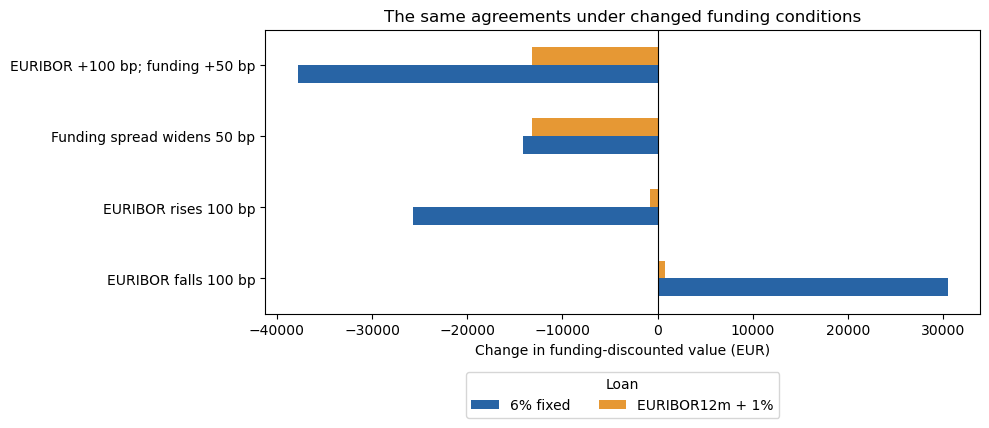

In [14]:
market_scenarios = [
    ("Base market", 0, 0),
    ("EURIBOR falls 100 bp", -100, 0),
    ("EURIBOR rises 100 bp", 100, 0),
    ("Funding spread widens 50 bp", 0, 50),
    ("EURIBOR +100 bp; funding +50 bp", 100, 50),
]
scenario_values = []
for scenario_name, benchmark_shift_bp, funding_shift_bp in market_scenarios:
    scenario = qs.Scenario(
        shocks=[
            qs.Shock(
                target="EURIBOR12m",
                value=benchmark_shift_bp / 10_000,
                shock_type=qs.ScenarioType.Absolute,
            ),
            qs.Shock(
                target="FUNDINGSPREAD",
                value=funding_shift_bp / 10_000,
                shock_type=qs.ScenarioType.Absolute,
            ),
        ]
    )
    with context, scenario:
        for label, instrument in [("6% fixed", fixed), ("EURIBOR12m + 1%", floating)]:
            result = context.evaluate(
                trade=qs.Trade(instrument=instrument, trade_date=valuation_date),
                requests=[qs.Request.Value, qs.Request.Cashflows],
            )
            coupons = result.cashflows.loc[
                result.cashflows.type.isin(["FixedRateCoupon", "FloatingRateCoupon"])
            ]
            scenario_values.append(
                {
                    "Scenario": scenario_name,
                    "Loan": label,
                    "EURIBOR quote shift (bp)": benchmark_shift_bp,
                    "Funding spread shift (bp)": funding_shift_bp,
                    "Projected interest (EUR)": coupons.amount.sum(),
                    "Funding value (EUR)": result.price,
                    "Profit or loss (EUR)": result.price
                    - funding_base_results[label].price,
                    "First-order funding effect (EUR)": (
                        funding_pv01.loc["Funding zero spreads", label]
                        * funding_shift_bp
                        if benchmark_shift_bp == 0
                        else None
                    ),
                }
            )
scenario_table = pd.DataFrame(scenario_values)
display(
    scenario_table.set_index(["Scenario", "Loan"]).style.format("{:,.2f}", na_rep="—")
)

scenario_pnl = scenario_table.pivot(
    index="Scenario", columns="Loan", values="Profit or loss (EUR)"
).reindex([name for name, _, _ in market_scenarios][1:])
ax = scenario_pnl.plot.barh(figsize=(10, 4.5), color=["#2864a5", "#e69834"])
ax.axvline(0, color="black", linewidth=0.8)
ax.set_xlabel("Change in funding-discounted value (EUR)")
ax.set_ylabel("")
ax.set_title("The same agreements under changed funding conditions")
ax.legend(title="Loan", loc="upper center", bbox_to_anchor=(0.5, -0.18), ncol=2)
plt.tight_layout()
plt.show()
context.curves = market.curves
context.fixed_income_policy = estr_policy


The fixed mortgage keeps its EUR 294,540.62 of contractual interest in every
scenario. A 100 bp EURIBOR increase lowers its funding-discounted value by
EUR 26,281.87. The floating mortgage loses only EUR 755.23 under that same move:
its future annual resets raise coupon income and offset much of the increased
benchmark funding cost. The first year's known fixing remains unchanged.

Funding-spread widening has no matching increase in borrower coupons. A 50 bp
widening leaves projected interest unchanged and reduces the fixed and floating
receipt values by EUR 13,889.63 and EUR 13,122.83 respectively. When EURIBOR also
rises 100 bp, floating interest over the term increases to EUR 305,048.19, while
its funding-discounted receipt value is EUR 233,640.77.

These scenarios retain the agreed principal schedules. The refinancing example
below adds the borrower's early-repayment response to the benchmark move.


## Early repayment and the life of the income stream

A borrower who prepays returns principal earlier and reduces the interest the
lender will receive later. Conditional prepayment rate, or CPR, expresses the
annual rate of early principal repayment on the balance that remains after
scheduled amortization.

For a regular monthly interval, the library converts annual CPR $c$ to a monthly
conditional probability

$$\pi=1-(1-c)^{1/12}.$$

With 25% annual CPR, this is about 2.37% per month. The pricer first pays scheduled
principal $Q_i$, then applies $\pi_i$ to the remaining balance. Future scheduled
interest and principal are weighted by the fraction expected to remain. This
produces an expected balance path while retaining the agreed contractual terms.

The prepayment interval has its own clock: a full monthly interval uses $1/12$
year, and partial or irregular intervals use Actual/365. Coupon interest in our
agreement continues to use Actual/360.

,Expected principal life (years),Expected interest (EUR),Value of receipts (EUR)
Prepayment assumption,,,
Scheduled payments only,19.37,"294,540.62","358,742.79"
12% annual CPR,6.68,"101,591.86","293,586.91"
25% annual CPR,3.34,"50,735.26","273,546.04"


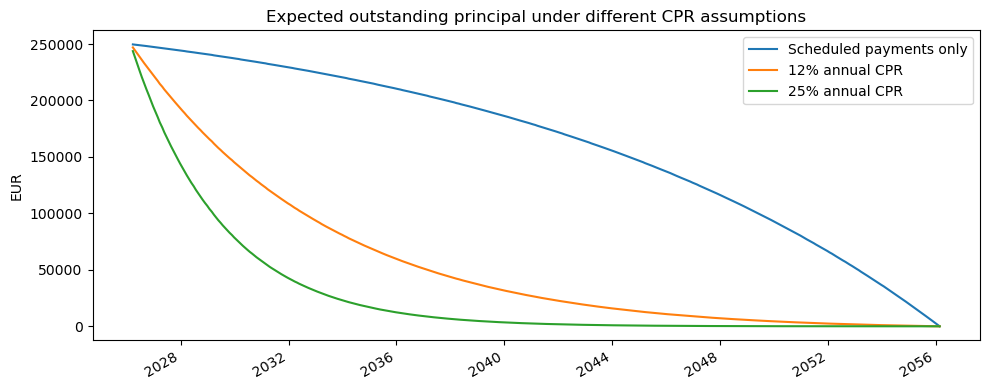

In [15]:
prepayment_models = {
    "Scheduled payments only": qs.PrepaymentModelConfiguration.no_prepayment(),
    "12% annual CPR": qs.PrepaymentModelConfiguration.constant_annual_cpr(cpr=0.12),
    "25% annual CPR": qs.PrepaymentModelConfiguration.constant_annual_cpr(cpr=0.25),
}
prepayment_results = {}
prepayment_comparison = []
with context:
    for label, model in prepayment_models.items():
        instrument = qs.Loan(
            identifier=label,
            coupons=[qs.FixedRateCoupon(rate=fixed_rate)],
            repayment=french,
            prepayment=model,
            **loan_terms,
        )
        result = context.evaluate(
            trade=qs.Trade(instrument=instrument, trade_date=valuation_date),
            requests=requests,
        )
        prepayment_results[label] = result
        principal_receipts = result.cashflows.loc[result.cashflows.type == "Redemption"]
        average_life = (
            sum(
                row.amount
                * qs.DayCounter.Actual365.year_fraction(
                    start=valuation_date, end=qs.Date.parse(s=row.payment_date)
                )
                for row in principal_receipts.itertuples(index=False)
            )
            / principal
        )
        prepayment_comparison.append(
            {
                "Prepayment assumption": label,
                "Expected principal life (years)": average_life,
                "Expected interest (EUR)": result.cashflows.loc[
                    result.cashflows.type == "FixedRateCoupon", "amount"
                ].sum(),
                "Value of receipts (EUR)": result.price,
            }
        )
display(pd.DataFrame(prepayment_comparison).set_index("Prepayment assumption"))

figure, axis = plt.subplots(figsize=(10, 4))
for label, result in prepayment_results.items():
    principal_receipts = (
        result.cashflows.loc[result.cashflows.type == "Redemption"]
        .groupby("payment_date")
        .amount.sum()
    )
    balance = principal - principal_receipts.cumsum()
    axis.plot(pd.to_datetime(balance.index), balance, label=label)
axis.set(
    title="Expected outstanding principal under different CPR assumptions", ylabel="EUR"
)
axis.legend()
figure.autofmt_xdate()
figure.tight_layout()
plt.show()


The expected principal life is the average time at which each euro of principal
returns, weighted by its repayment amount. Scheduled amortization gives this
mortgage a principal life of 19.37 years. At 12% annual CPR it falls to 6.68 years;
at 25% CPR it falls to 3.34 years, despite the same thirty-year contractual term.

At 25% CPR, expected interest falls from EUR 294,540.62 to EUR 50,735.26, and the
receipt value falls from EUR 358,742.79 to EUR 273,546.04. The lender receives
principal much sooner but loses decades of above-market fixed coupon income.

The library also supports a dated CPR curve through
`PrepaymentModelConfiguration.dated_annual_cpr`. It uses the latest annual CPR
whose effective date has been reached at the start of the interval, zero before
the first date, and the last supplied rate for subsequent intervals. This can
represent a seasoning pattern or an expected change in borrower behaviour.


### Prepayment changes the par lending rate and market sensitivity

We now compare the fixed, floating, and introductory-fixed agreements against the
same EURIBOR-plus-funding-spread curve used above. For each agreement we retain its
original principal schedule and change only the prepayment assumption. Keeping the
shaped funding curve makes the effect of earlier repayment on the par lending
hurdle visible; under a nearly flat ESTR curve, constant CPR can have very little
effect on the par fixed coupon even while materially reducing value and duration.

`FairRate` includes the prepayment model in every trial valuation. With the default
`rebuild_amortization_for_fair_rate=False`, it changes the uniform fixed coupon or
floating spread without rebuilding the contractual principal amounts. The table
reports the resulting par rate and its change in basis points from no prepayment.
These are alternative lending terms, not changes to the borrower's agreed coupon.

**Targeted fair rates:** `qs.Request.FairRate(0)` selects the first contiguous
coupon segment; `qs.Request.FairRate(1)` selects the second. For the introductory
loan the latter bootstraps the first coupon, repays remaining capital at that
prefix end, locks the coupon, then solves the later spread. Each evaluation
returns one scalar `fair_rate`. The comparison below keeps its original value
and risk columns; the following cell demonstrates both segment requests.

The second table shows signed EUR PV01: the first-order value change for a parallel
**+1 bp** move in each named group of market inputs. The change columns subtract
the corresponding no-prepayment exposure. These are sensitivities of the original
agreed loan, not derivatives of the solved fair rate and not sensitivities to CPR.
For constant CPR, repayment probabilities do not respond to market quotes; the
refinancing example below adds that response. The first EURIBOR fixing remains
known and unchanged.

In [16]:
prepayment_agreements = {
    "6% fixed": fixed,
    "EURIBOR12m + 1%": floating,
    "Introductory fixed": mixed,
}
prepayment_funding_loans = {}
for loan_label, agreement in prepayment_agreements.items():
    for prepayment_label, model in prepayment_models.items():
        terms = agreement.to_dict()
        terms["identifier"] = f"{loan_label}: {prepayment_label}"
        terms["prepayment"] = model.to_dict()
        prepayment_funding_loans[(loan_label, prepayment_label)] = qs.Loan.from_dict(
            obj=terms
        )

prepayment_funding_results = {}
prepayment_rate_rows = []
prepayment_risk_rows = []
context.curves = market.curves + [spread_configuration, funding_configuration]
context.fixed_income_policy = funding_policy
try:
    with context:
        for (
            loan_label,
            prepayment_label,
        ), instrument in prepayment_funding_loans.items():
            pricing_requests = [qs.Request.Value, qs.Request.Sensitivities]
            if loan_label != "Introductory fixed":
                pricing_requests.append(qs.Request.FairRate(0))
            result = context.evaluate(
                trade=qs.Trade(instrument=instrument, trade_date=valuation_date),
                requests=pricing_requests,
            )
            prepayment_funding_results[(loan_label, prepayment_label)] = result
            prepayment_rate_rows.append(
                {
                    "Loan": loan_label,
                    "Prepayment assumption": prepayment_label,
                    "Funding value (EUR)": result.price,
                    "Par fixed coupon (%)": (
                        result.fair_rate * 100 if loan_label == "6% fixed" else None
                    ),
                    "Par EURIBOR margin (bp)": (
                        result.fair_rate * 10_000
                        if loan_label == "EURIBOR12m + 1%"
                        else None
                    ),
                    "Fair-rate support": (
                        "Separate indexed requests"
                        if loan_label == "Introductory fixed"
                        else "Native FairRate"
                    ),
                }
            )
            risk = result.sensitivities
            prepayment_risk_rows.append(
                {
                    "Loan": loan_label,
                    "Prepayment assumption": prepayment_label,
                    "ESTR PV01 (EUR)": risk.loc[
                        risk.pillar.str.contains("ESTR"), "value"
                    ].sum()
                    * 0.0001,
                    "EURIBOR PV01 (EUR)": risk.loc[
                        risk.pillar.str.contains("EURIBOR"), "value"
                    ].sum()
                    * 0.0001,
                    "Funding spread PV01 (EUR)": risk.loc[
                        risk.pillar.str.contains("FUNDINGSPREAD"), "value"
                    ].sum()
                    * 0.0001,
                }
            )
finally:
    context.curves = market.curves
    context.fixed_income_policy = estr_policy

prepayment_rate_table = pd.DataFrame(prepayment_rate_rows).set_index(
    ["Loan", "Prepayment assumption"]
)
prepayment_rate_baseline = prepayment_rate_table.xs("Scheduled payments only", level=1)
prepayment_rate_table["Change in par fixed coupon (bp)"] = (
    prepayment_rate_table["Par fixed coupon (%)"]
    - prepayment_rate_table.index.get_level_values("Loan").map(
        prepayment_rate_baseline["Par fixed coupon (%)"]
    )
) * 100
prepayment_rate_table["Change in par EURIBOR margin (bp)"] = prepayment_rate_table[
    "Par EURIBOR margin (bp)"
] - prepayment_rate_table.index.get_level_values("Loan").map(
    prepayment_rate_baseline["Par EURIBOR margin (bp)"]
)
display(
    prepayment_rate_table.style.format(
        {
            "Funding value (EUR)": "{:,.2f}",
            "Par fixed coupon (%)": "{:.6f}",
            "Par EURIBOR margin (bp)": "{:.4f}",
            "Change in par fixed coupon (bp)": "{:+.4f}",
            "Change in par EURIBOR margin (bp)": "{:+.4f}",
        },
        na_rep="Not applicable",
    )
)

prepayment_risk_table = pd.DataFrame(prepayment_risk_rows).set_index(
    ["Loan", "Prepayment assumption"]
)
for column in list(prepayment_risk_table.columns):
    baseline = prepayment_risk_table[column].xs("Scheduled payments only", level=1)
    prepayment_risk_table[f"Change in {column}"] = prepayment_risk_table[
        column
    ] - prepayment_risk_table.index.get_level_values("Loan").map(baseline)
display(prepayment_risk_table.style.format("{:+,.2f}"))


With no prepayment, the funding-based par fixed coupon is **5.490206%**. It falls
to **5.094379%** at 12% CPR and **4.826445%** at 25% CPR, a reduction of 66.38 bp
from the scheduled-only case. The par EURIBOR margin falls from **112.2190 bp**
to **99.9181 bp** and **90.2726 bp**. Earlier repayment reduces exposure to the
more expensive later funding periods in this particular rising spread curve;
prepayment does not universally lower the required lending rate.

For the agreed 6% fixed loan, the funding-spread PV01 changes from **EUR -289.67**
to **EUR -74.86** at 25% CPR. Its EURIBOR PV01 changes from **EUR -285.46** to
**EUR -73.70**. Both losses for a +1 bp move become smaller as the expected
income stream shortens. The mixed loan's funding-spread PV01 likewise changes
from **EUR -264.72** to **EUR -71.11**, even though its fair-rate solve is unsupported.

Not every net sensitivity shrinks in magnitude. The floating loan's EURIBOR PV01
changes from **EUR -7.48** to **EUR -18.93**: prepayment changes the timing of both
future reset income and funding costs, so their offset changes. Its funding-spread
PV01 still falls in magnitude, from **EUR -273.54** to **EUR -72.48**. These signed
exposures describe the original coupons and the chosen market, not a general
monotonic relationship between CPR and every risk measure.

### Linking prepayment to a refinancing incentive

A constant CPR gives a chosen repayment speed. A refinancing model makes that
speed respond to rates. The library's incentive specification uses

$$c=\min\left(c_{\max},\ c_{\mathrm{base}}+
\alpha\max(r_{\mathrm{coupon}}-r_{\mathrm{benchmark}},0)\right).$$

We choose base CPR of 2%, an incentive multiplier of 4, and a 40% annual cap.
A one-percentage-point increase in a positive coupon-minus-benchmark gap adds
four percentage points to annual CPR, until the cap binds. The configured
EURIBOR12m index supplies the refinancing benchmark. This benchmark contains
the index rate; a borrower's replacement lending spread, fees, and transaction
costs would require a richer incentive specification.

The following scenarios move the EURIBOR deposit and swap quotes by 100 basis points in
either direction while retaining the ESTR discount inputs. They show how the
prepayment assumption transmits a benchmark-rate move to a fixed-rate loan's
future interest income.

We set `refinancing_benchmark_index` with `PricerConfiguration.loan(...)`,
passing the typed `qs.MarketIndex.EURIBOR12m` benchmark. The same `context.evaluate(...)` entry point dispatches
to the Rust loan pricer for the base value and each market scenario. Discounting
uses `context.fixed_income_policy`; the refinancing benchmark and the discount
curve are separate choices. We restore the default loan configuration after
the comparison.


In [17]:
refinancing_loan = qs.Loan(
    identifier="REFINANCING",
    coupons=[qs.FixedRateCoupon(rate=fixed_rate)],
    repayment=french,
    prepayment=qs.PrepaymentModelConfiguration.refinancing_incentive(
        base_cpr=0.02, incentive_multiplier=4.0, maximum_cpr=0.40
    ),
    **loan_terms,
)
context.pricer_configurations = [qs.PricerConfiguration.loan(
    refinancing_benchmark_index=qs.MarketIndex.EURIBOR12m,
)]
try:
    with context:
        refinancing_result = context.evaluate(
            trade=qs.Trade(instrument=refinancing_loan, trade_date=valuation_date),
            requests=requests,
        )

    refinancing_scenarios = []
    for shift_bp in [-100, 0, 100]:
        scenario = qs.Scenario(
            shocks=[
                qs.Shock(
                    target="EURIBOR12m",
                    value=shift_bp / 10_000,
                    shock_type=qs.ScenarioType.Absolute,
                )
            ]
        )
        with context, scenario:
            result = context.evaluate(
                trade=qs.Trade(instrument=refinancing_loan, trade_date=valuation_date),
                requests=[qs.Request.Value, qs.Request.Cashflows],
            )
        refinancing_scenarios.append(
            {
                "EURIBOR quote shift (bp)": shift_bp,
                "Expected prepayment (EUR)": result.cashflows.loc[
                    result.cashflows.leg_index == 1, "amount"
                ].sum(),
                "Expected interest (EUR)": result.cashflows.loc[
                    result.cashflows.type == "FixedRateCoupon", "amount"
                ].sum(),
                "Value of receipts (EUR)": result.price,
                "Value change (EUR)": result.price - refinancing_result.price,
            }
        )
finally:
    context.pricer_configurations = [loan_configuration]
display(pd.DataFrame(refinancing_scenarios).set_index("EURIBOR quote shift (bp)"))


,Expected prepayment (EUR),Expected interest (EUR),Value of receipts (EUR),Value change (EUR)
EURIBOR quote shift (bp),,,,
-100,"216,049.18","90,616.36","288,998.33","-11,216.45"
0,"193,144.40","121,713.08","300,214.78",0.00
100,"146,727.94","171,328.44","317,268.71","17,053.93"


A 100 bp fall in the EURIBOR quotes raises expected early repayment from
EUR 188,873.10 to EUR 214,714.62. The lender gives up more future coupon income,
and receipt value falls by EUR 12,219.72 while the ESTR discount inputs stay
fixed. A rising benchmark reduces the incentive and allows that income to
persist. The prepayment model therefore gives the fixed mortgage an additional
exposure to the refinancing benchmark over its remaining life.


## Borrower default and recovery

So far the borrower has met every payment that remained outstanding. We now
attach the `BORROWER` survival curve, constructed from the sample CDS quotes,
and assume recovery of 40% of opening principal upon default. The credit-curve
configuration uses the same recovery assumption when interpreting those quotes.

Let $S_i$ be survival to payment date $t_i$, conditional on survival at valuation.
For a period with interest $I_i$ and principal $Q_i$, the library's expected
receipt, before discounting, is

$$S_i(I_i+Q_i)+R B_{i-1}(S_{i-1}-S_i).$$

Survival weights the scheduled receipt. The second term adds recovery against
the probability of default during the interval. Recovery is paid at the
period's payment date using opening principal; this gives the library a discrete
approximation to the timing of default recoveries.

The cashflow report identifies scheduled receipts with `leg_index=0`, prepayment
with `leg_index=1`, and recovery with `leg_index=2`. Recovery uses the existing
`ConstantAmount` cashflow type. Here the loan has scheduled amortization and
borrower credit risk.

In [18]:
credit_loan = qs.Loan(
    identifier="BORROWER-CREDIT",
    coupons=[qs.FixedRateCoupon(rate=fixed_rate)],
    repayment=french,
    credit_index=qs.MarketIndex.credit(name="BORROWER"),
    recovery=0.40,
    **loan_terms,
)
context.credit_curve_configurations = market.credit_curves
with context:
    credit_result = context.evaluate(
        trade=qs.Trade(instrument=credit_loan, trade_date=valuation_date),
        requests=requests,
    )

credit_payments = credit_result.cashflows.pivot_table(
    index="payment_date", columns="type", values="amount", aggfunc="sum", fill_value=0
).rename(
    columns={
        "FixedRateCoupon": "Expected interest",
        "Redemption": "Expected scheduled principal",
        "ConstantAmount": "Expected recovery",
    }
)
display(credit_payments.head(6))
display(
    pd.DataFrame(
        [
            {
                "Borrower assumption": "All scheduled payments received",
                "Value of receipts (EUR)": fixed_result.price,
            },
            {
                "Borrower assumption": "CDS survival curve, 40% recovery",
                "Value of receipts (EUR)": credit_result.price,
            },
        ]
    ).set_index("Borrower assumption")
)


type,Expected recovery,Expected interest,Expected scheduled principal
payment_date,,,
2026-03-24,129.55,"1,165.16",345.50
2026-04-24,143.03,"1,286.36",222.13
2026-05-25,142.70,"1,241.97",264.35
2026-06-24,137.75,"1,280.22",224.01
2026-07-24,137.44,"1,236.09",266.06
2026-08-24,141.67,"1,274.09",225.90


,Value of receipts (EUR)
Borrower assumption,
All scheduled payments received,"358,742.79"
"CDS survival curve, 40% recovery","282,425.79"


The declining contractual balance reduces the principal exposed to default as
the mortgage seasons. Expected recovery replaces part of the income lost on
default, and receipt value falls from EUR 358,742.79 to EUR 282,425.79 under
these credit assumptions. The long repayment term leaves substantial principal
exposed during later years. A bullet structure would keep the original advance
outstanding until maturity and retain still more exposure to borrower default.


## Reading the market-quote exposure

The price sensitivities describe which market inputs drive the value of the
income stream. Each `value` is a derivative $\partial V/\partial q$ with respect
to a labelled quote. Rate quotes are decimal fractions, so multiplying by
$0.0001$ gives the approximate EUR price change for a one-basis-point increase.

We compare the original fixed loan, the floating loan, and the fixed loan with
refinancing-sensitive prepayment. The table keeps the market-quote labels so we
can distinguish discounting exposure from the EURIBOR benchmark exposure.

In [19]:
quote_exposures = []
for label, result in [
    ("6% fixed", fixed_result),
    ("Floating", floating_result),
    ("Fixed with refinancing prepayment", refinancing_result),
]:
    risk = result.sensitivities.copy()
    risk["Loan"] = label
    risk["EUR change for +1bp"] = risk.value * 0.0001
    quote_exposures.append(risk[["pillar", "Loan", "EUR change for +1bp"]])

risk_table = pd.concat(quote_exposures).pivot_table(
    index="pillar",
    columns="Loan",
    values="EUR change for +1bp",
    aggfunc="sum",
    fill_value=0,
)
display(risk_table.style.format("{:+,.4f}"))


Loan,6% fixed,Fixed with refinancing prepayment,Floating
pillar,,,
FixedRateDeposit_EUR_ESTR_1D,-0.0918,-0.0537,-0.0848
FixedRateDeposit_EUR_ESTR_1Y,-0.8848,-3.5728,-0.7889
FixedRateDeposit_EUR_ESTR_2Y,-1.4953,-6.1194,-1.3597
FixedRateDeposit_EUR_ESTR_3Y,-3.1632,-10.7715,-2.9320
FixedRateDeposit_EUR_EURIBOR12m_1D,+0.0000,+0.0283,+0.0693
FixedRateDeposit_EUR_EURIBOR12m_1Y,+0.0000,-8.0752,-24.3001
OIS_EUR_ESTR_10Y,-42.3523,-36.9711,-40.5537
OIS_EUR_ESTR_15Y,-68.7996,-35.6489,-63.8752
OIS_EUR_ESTR_20Y,-99.5151,-35.2182,-90.9255


The fixed loan's exposure comes from discounting its agreed receipts. The
floating loan also responds to the EURIBOR quotes used to project its future
annual resets. Its first annual fixing is already known, so that year's coupon
income has been set; the remaining 29 annual resets supply the future projection
exposure.

The refinancing-sensitive fixed loan adds a different EURIBOR channel. Higher
benchmark rates reduce expected prepayment and preserve some of its above-market
coupon income. Its quote exposure reflects that change in repayment behaviour,
alongside the value effect of the discount curve.

## Reconciling the mortgage calculations

The contractual schedule provides an independent way to reconstruct the French
payment using monthly accrual factors. We also check conservation of principal
with prepayment, then discount the reported expected receipts to reproduce
value under fixed, floating, prepayment and credit assumptions.


In [20]:
accrual_dates = [
    valuation_date + qs.Period(length=month, units=qs.TimeUnit.Months)
    for month in range(monthly_payments + 1)
]
contractual_factors = []
discount_product = 1.0
for start, end in zip(accrual_dates, accrual_dates[1:]):
    fraction = qs.DayCounter.Actual360.year_fraction(start, end)
    discount_product /= 1 + annual_fixed_coupon * fraction
    contractual_factors.append(discount_product)
independent_payment = principal / sum(contractual_factors)

pv_checks = []
with context:
    discount_curve = context.curve(qs.MarketIndex.ESTR)
    for label, result in [
        ("Fixed", fixed_result),
        ("Floating", floating_result),
        ("25% CPR", prepayment_results["25% annual CPR"]),
        ("Credit", credit_result),
    ]:
        reconstructed_pv = sum(
            row.amount * discount_curve.discount_factor(qs.Date.parse(row.payment_date))
            for row in result.cashflows.itertuples(index=False)
        )
        pv_checks.append(
            {
                "Assumption": label,
                "Native PV (EUR)": result.price,
                "Receipt PV (EUR)": reconstructed_pv,
                "Residual (EUR)": reconstructed_pv - result.price,
            }
        )
print(f"Independent French monthly payment: EUR {independent_payment:,.6f}.")
display(pd.DataFrame(pv_checks).set_index("Assumption"))


Independent French monthly payment: EUR 1,512.612844.


,Native PV (EUR),Receipt PV (EUR),Residual (EUR)
Assumption,,,
Fixed,"358,742.79","358,742.79",-0.00
Floating,"331,004.10","331,004.10",0.00
25% CPR,"273,546.04","273,546.04",0.00
Credit,"282,425.79","282,425.79",0.00


### Reprice the solved fixed coupons and check funding-spread risk

A par coupon is verified by **constructing the alternative agreement**. When
principal is retained, its amortization basis stays at the original 6%; when
rebuilt, it uses the solved coupon. We also compare the signed funding PV01
with a central ±1 bp spread-pillar shock. The original lender contracts,
including known historical fixings, remain unchanged.


In [21]:
par_checks = []
with context:
    for row in fair_rate_comparison:
        coupon = row["Par fixed coupon (%)"] / 100
        rebuild = row["Principal assumption"] == "Rebuild principal at the trial rate"
        terms = fixed.to_dict()
        terms["coupons"] = [
            qs.FixedRateCoupon(
                rate=qs.InterestRate(
                    rate=coupon,
                    day_counter=qs.DayCounter.Actual360,
                    compounding=qs.Compounding.Simple,
                    frequency=qs.Frequency.Annual,
                )
            ).to_dict()
        ]
        terms["amortization_rate"] = coupon if rebuild else annual_fixed_coupon
        alternative = qs.Loan.from_dict(terms)
        value = context.evaluate(
            trade=qs.Trade(alternative, valuation_date),
            requests=[qs.Request.Value],
        ).price
        par_checks.append(
            {
                "Principal assumption": row["Principal assumption"],
                "PV at par (EUR)": value,
            }
        )

context.curves = market.curves + [spread_configuration, funding_configuration]
context.fixed_income_policy = funding_policy
try:
    bumped_values = {}
    for bump in [-1e-4, 1e-4]:
        with context, qs.Scenario(
            shocks=[
                qs.Shock(
                    target="FUNDINGSPREAD",
                    value=bump,
                    shock_type=qs.ScenarioType.Absolute,
                )
            ]
        ):
            bumped_values[bump] = context.evaluate(
                trade=qs.Trade(fixed, valuation_date),
                requests=[qs.Request.Value],
            ).price
    finite_difference_pv01 = (bumped_values[1e-4] - bumped_values[-1e-4]) / 2
    aad_pv01 = funding_pv01.loc["Funding zero spreads", "6% fixed"]
finally:
    context.curves = market.curves
    context.fixed_income_policy = estr_policy
print(
    f"Funding +1 bp PV01: AAD EUR {aad_pv01:.6f}, central bump EUR {finite_difference_pv01:.6f}."
)
display(pd.DataFrame(par_checks).set_index("Principal assumption"))


Funding +1 bp PV01: AAD EUR -295.460491, central bump EUR -295.460663.


,PV at par (EUR)
Principal assumption,
Keep the agreed principal schedule,"250,000.00"
Rebuild principal at the trial rate,"250,000.00"


Funding and repayment timing determine the value of the mortgage's expected
income. Earlier principal return reduces exposure to later funding periods,
while floating resets partly offset changes in benchmark discounting. The
comparisons above keep contractual principal fixed unless fair-rate trials
explicitly rebuild it.

When adapting the study, review the borrower assumptions alongside the market
curves. Refinancing fees, servicing costs, embedded-option time value and
stochastic credit/rate dependence would require additional modelling.


### Indexed loan fair-rate requests
Each target is requested separately. The returned scalar is the annual fixed coupon for segment 0 and the floating spread for segment 1.


In [22]:
with context:
    mixed_trade = qs.Trade(instrument=mixed, trade_date=valuation_date)
    segment_rates = [
        context.evaluate(trade=mixed_trade,
                        requests=[qs.Request.FairRate(target)]).fair_rate
        for target in range(2)
    ]
pd.DataFrame({"Segment (zero-based)": [0, 1], "Fair coupon / spread": segment_rates})


,Segment (zero-based),Fair coupon / spread
0,0,0.03
1,1,-0.02
